# Oil and Gas HSE Incident Analysis Using Python

**Project type:** Portfolio project using simulated data  
**Tools:** Python, Pandas, NumPy, Matplotlib

> **Data disclaimer:** This project uses simulated data for learning and portfolio demonstration. The results do not describe the performance of a real company or actual workplace incidents.

## 1. Project Overview

This project uses Python to explore a simulated Health, Safety and Environment (HSE) incident dataset for an oil and gas operational setting. The analysis examines incident types, severity, recorded causes, work activities, site distributions, near misses, and monthly incident patterns.

The objective is to demonstrate a practical data-analysis workflow: loading data, inspecting data quality, cleaning inconsistent values, exploring patterns, visualising results, and communicating cautious recommendations.

## 2. Business Problem and Objectives

### Business problem

HSE incident records can help identify recurring event categories and areas that may warrant further investigation. The usefulness of analysis depends on data quality, consistent classification, and appropriate interpretation.

### Objectives

- Inspect the structure and quality of the dataset.
- Remove exact duplicate rows and standardise selected categorical fields.
- Identify missing values and investigate unusual numeric values.
- Explore incident types, severity, recorded causes, sites, and work activities.
- Examine near-miss patterns and monthly incident counts.
- Summarise recommendations while acknowledging data limitations.

## 3. Dataset Description

The source dataset is expected to contain 302 rows and 14 columns before exact duplicate removal. The fields describe incident identifiers, dates, locations, departments, incident types, severity, work activities, recorded causes, body parts affected, lost workdays, shifts, contractors, corrective-action durations, and status.

| Column | Description |
|---|---|
| `Incident_ID` | Incident record identifier |
| `Incident_Date` | Date associated with the incident |
| `Site` | Operational location |
| `Department` | Department associated with the record |
| `Incident_Type` | Recorded incident category |
| `Severity` | Recorded severity classification |
| `Activity` | Work activity associated with the event |
| `Primary_Cause` | Recorded primary cause category |
| `Body_Part_Affected` | Body part recorded for relevant injury cases |
| `Lost_Work_Days` | Number of workdays lost |
| `Shift` | Recorded work shift |
| `Contractor` | Contractor or in-house team |
| `Corrective_Action_Days` | Recorded corrective-action duration |
| `Status` | Current recorded status |

A blank body-part field may not apply to incidents that did not involve an injury. The meaning and completeness of each field should be considered before interpreting results.

## 4. Data Loading and Initial Inspection

The dataset is loaded with Pandas. Initial inspection checks the dimensions, column names, data types, sample records, missing values, and exact duplicate rows. This establishes a baseline before cleaning.

In [17]:
# Import the libraries used in this project.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the CSV file. Keep it in the same folder as this notebook,
# or update the path below to match your file location.
df = pd.read_csv("oil_gas_hse_raw_data.csv")

# Inspect the dataset's dimensions and structure.
print("Dataset shape:", df.shape)
display(df.head())
df.info()

# Review missing values and duplicate records before cleaning.
print("\nMissing values by column:")
display(df.isnull().sum())
print("\nExact duplicate rows:", df.duplicated().sum())
print("Duplicate incident IDs:", df["Incident_ID"].duplicated().sum())

Dataset shape: (302, 14)


,Incident_ID,Incident_Date,Site,Department,Incident_Type,Severity,Activity,Primary_Cause,Body_Part_Affected,Lost_Work_Days,Shift,Contractor,Corrective_Action_Days,Status
0,HSE-0224,2025-05-05,Onshore Base,Operations,Property Damage,Medium,Working at Height,Unsafe Act,NaN,0,Day,In-house,NaN,Closed
1,HSE-0058,2025-02-10,Gas Processing Plant,Security,First Aid,Low,Driving,Unsafe Condition,NaN,0,Day,Westline Engineering,19.0,Closed
2,HSE-0264,2025-12-19,Offshore Platform B,Maintenance,near miss,Low,Confined Space Entry,Weather,NaN,0,Night,Westline Engineering,15.0,Closed
3,HSE-0067,2026-04-13,Onshore Base,Security,Near Miss,Low,Material Handling,Unsafe Condition,NaN,0,Night,Nigerian Marine Support,42.0,open
4,HSE-0115,2025-12-13,Offshore Platform A,Marine,Property Damage,Low,Housekeeping,Inadequate Training,NaN,0,Night,Delta Industrial Services,30.0,Open


<class 'pandas.DataFrame'>
RangeIndex: 302 entries, 0 to 301
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Incident_ID             302 non-null    str    
 1   Incident_Date           297 non-null    str    
 2   Site                    302 non-null    str    
 3   Department              295 non-null    str    
 4   Incident_Type           302 non-null    str    
 5   Severity                298 non-null    str    
 6   Activity                302 non-null    str    
 7   Primary_Cause           296 non-null    str    
 8   Body_Part_Affected      94 non-null     str    
 9   Lost_Work_Days          302 non-null    int64  
 10  Shift                   302 non-null    str    
 11  Contractor              298 non-null    str    
 12  Corrective_Action_Days  297 non-null    float64
 13  Status                  302 non-null    str    
dtypes: float64(1), int64(1), str(12)
memory usage: 70.7 K

Incident_ID                 0
Incident_Date               5
Site                        0
Department                  7
Incident_Type               0
Severity                    4
Activity                    0
Primary_Cause               6
Body_Part_Affected        208
Lost_Work_Days              0
Shift                       0
Contractor                  4
Corrective_Action_Days      5
Status                      0
dtype: int64


Exact duplicate rows: 2
Duplicate incident IDs: 2


## 5. Data Cleaning and Preparation

Data cleaning was performed to improve consistency and identify values that may affect analysis. The raw DataFrame (`df`) is preserved, and changes are made to a separate working copy (`df_clean`).

### 5.1 Duplicate Removal

Exact duplicate rows were removed from the working copy so identical records would not be counted more than once. Records sharing an incident identifier should not be removed automatically unless their details confirm they are duplicates.

In [18]:
# Create a working copy so the original data remains unchanged.
df_clean = df.copy()

# Remove exact duplicate rows from the working copy.
df_clean = df_clean.drop_duplicates()

# Review the resulting dimensions and remaining exact duplicates.
print("Original dataset shape:", df.shape)
print("Shape after exact duplicate removal:", df_clean.shape)
print("Exact duplicate rows remaining:", df_clean.duplicated().sum())

Original dataset shape: (302, 14)
Shape after exact duplicate removal: (300, 14)
Exact duplicate rows remaining: 0


### 5.2 Category Standardisation

Categorical columns were reviewed for inconsistent spacing, letter case, and known label variations. Standardisation helps ensure equivalent categories are grouped consistently. The `Critical` severity level remains separate from `High`.

In [19]:
# Standardise incident type labels and correct known variations.
df_clean["Incident_Type"] = (
    df_clean["Incident_Type"]
    .str.strip()
    .str.lower()
    .replace({"near-miss": "near miss", "near misss": "near miss"})
    .str.title()
)

# Standardise severity labels while preserving Critical as a separate category.
df_clean["Severity"] = (
    df_clean["Severity"]
    .str.strip()
    .str.lower()
    .replace({"minor": "low", "moderate": "medium", "major": "high"})
    .str.title()
)

# Standardise department names and preserve the HSE abbreviation.
df_clean["Department"] = (
    df_clean["Department"].str.strip().str.title().replace({"Hse": "HSE"})
)

# Standardise the presentation of site and other categorical fields.
df_clean["Site"] = df_clean["Site"].str.strip().str.title()
df_clean["Primary_Cause"] = df_clean["Primary_Cause"].str.strip().str.title()
df_clean["Activity"] = df_clean["Activity"].str.strip().str.title()
df_clean["Status"] = (
    df_clean["Status"].str.strip().str.title().replace({
        "Pending Action": "Pending Corrective Action",
        "Investigation": "Under Investigation"
    })
)
df_clean["Contractor"] = df_clean["Contractor"].str.strip().str.title()

### 5.3 Missing Values Assessment

Missing values were reviewed to understand which columns contain incomplete records. Values were not automatically filled because the appropriate treatment depends on the field and incident context. A missing body-part value, for example, may be non-applicable to a near miss or property-damage event.

In [20]:
# Count missing values in each column.
missing_values = df_clean.isnull().sum()

# Calculate the percentage of missing values in each column.
missing_percentage = (df_clean.isnull().mean() * 100).round(2)

# Review the missing-value profile.
print("Missing values by column:")
display(missing_values[missing_values > 0])
print("Percentage of missing values by column:")
display(missing_percentage[missing_percentage > 0])

Missing values by column:


Incident_Date               5
Department                  7
Severity                    4
Primary_Cause               6
Body_Part_Affected        206
Contractor                  4
Corrective_Action_Days      5
dtype: int64

Percentage of missing values by column:


Incident_Date              1.67
Department                 2.33
Severity                   1.33
Primary_Cause              2.00
Body_Part_Affected        68.67
Contractor                 1.33
Corrective_Action_Days     1.67
dtype: float64

### 5.4 Date Conversion and Validation

The incident date field contains mixed date representations. Dates are converted to a datetime type for time-based analysis. Slash-separated dates may be ambiguous when the source convention is not confirmed; date-based findings should therefore be interpreted cautiously.

In [21]:
# Convert mixed date representations to datetime.
# Unrecognised values become missing values instead of stopping conversion.
df_clean["Incident_Date"] = pd.to_datetime(
    df_clean["Incident_Date"],
    format="mixed",
    dayfirst=False,
    errors="coerce"
)

# Count missing dates after conversion. This includes original blanks and
# any values that could not be parsed by the conversion rule.
missing_dates_after_conversion = df_clean["Incident_Date"].isna().sum()
print("Missing dates after conversion:", missing_dates_after_conversion)

Missing dates after conversion: 5


### 5.5 Data Quality Checks and Corrections

Negative lost-workday values are invalid and require investigation. The identified negative value is set to missing rather than replaced with an invented number. Long corrective-action durations are flagged for review but not automatically changed because they may reflect genuine delays.

In [22]:
# Replace invalid negative lost-workday values with missing values.
df_clean.loc[df_clean["Lost_Work_Days"] < 0, "Lost_Work_Days"] = np.nan

# Flag unusually long corrective-action durations for review.
# The 90-day threshold is a screening rule, not proof of an error.
long_corrective_actions = df_clean[df_clean["Corrective_Action_Days"] > 90]

# Review the cleaned dataset's shape and remaining data-quality issues.
print("Cleaned dataset shape:", df_clean.shape)
print("Exact duplicate rows remaining:", df_clean.duplicated().sum())
print("Missing values by column:")
display(df_clean.isnull().sum())
print("Corrective-action records above 90 days:", len(long_corrective_actions))

Cleaned dataset shape: (300, 14)
Exact duplicate rows remaining: 0
Missing values by column:


Incident_ID                 0
Incident_Date               5
Site                        0
Department                  7
Incident_Type               0
Severity                    4
Activity                    0
Primary_Cause               6
Body_Part_Affected        206
Lost_Work_Days              1
Shift                       0
Contractor                  4
Corrective_Action_Days      5
Status                      0
dtype: int64

Corrective-action records above 90 days: 1


## 6. Exploratory Data Analysis (EDA)

Exploratory Data Analysis was conducted to understand the distribution and patterns of incidents in the cleaned dataset. The analysis examines incident types, severity, recorded causes, sites, near misses, work activities, and monthly incident counts. The analysis is descriptive and does not establish causation or definitive safety rankings.

### 6.1 Incident Type Distribution

The incident type distribution shows which categories are most frequently recorded. Frequency alone does not determine severity or risk.

Incident_Type
Near Miss                105
First Aid                 62
Property Damage           45
Medical Treatment         38
Environmental Release     26
Lost Time Injury          24
Name: count, dtype: int64

Incident_Type
Near Miss                35.00
First Aid                20.67
Property Damage          15.00
Medical Treatment        12.67
Environmental Release     8.67
Lost Time Injury          8.00
Name: proportion, dtype: float64

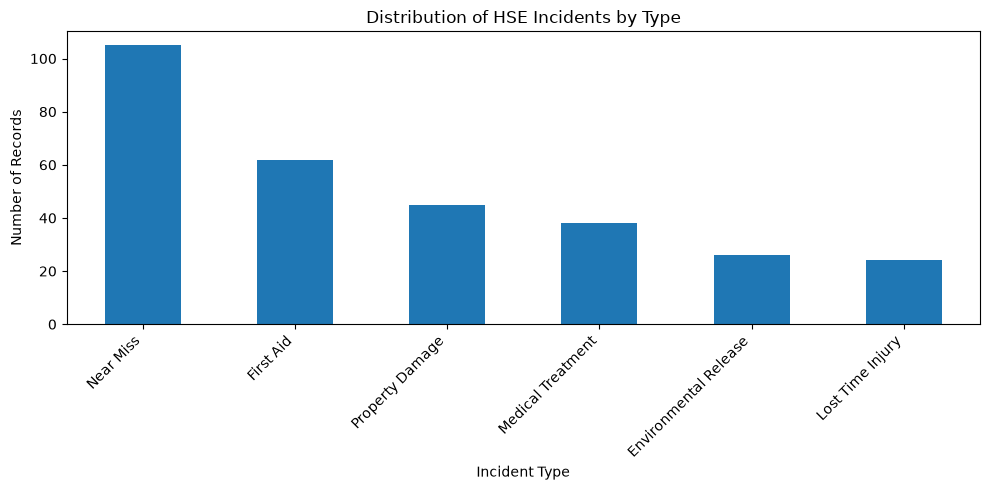

In [23]:
# Count records in each incident type category.
incident_type_counts = df_clean["Incident_Type"].value_counts()
incident_type_percentage = (df_clean["Incident_Type"].value_counts(normalize=True) * 100).round(2)
display(incident_type_counts)
display(incident_type_percentage)

# Compare the number of records in each incident type.
incident_type_counts.plot(kind="bar", figsize=(10, 5))
plt.title("Distribution of HSE Incidents by Type")
plt.xlabel("Incident Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 6.2 Incident Severity Distribution

The severity distribution shows how records are classified across Low, Medium, High, and Critical. Missing severity values should be considered when interpreting percentages.

Severity
Low         142
Medium       80
High         73
Critical      1
Name: count, dtype: int64

Severity
Low         47.97
Medium      27.03
High        24.66
Critical     0.34
Name: proportion, dtype: float64

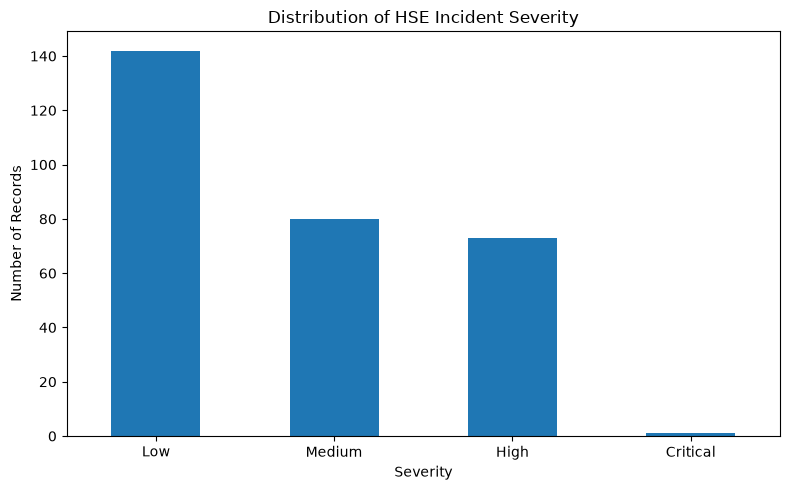

In [24]:
# Count and calculate percentages for recorded severity categories.
severity_counts = df_clean["Severity"].value_counts()
severity_percentage = (df_clean["Severity"].value_counts(normalize=True) * 100).round(2)
display(severity_counts)
display(severity_percentage)

# Compare the recorded severity categories.
severity_counts.plot(kind="bar", figsize=(8, 5))
plt.title("Distribution of HSE Incident Severity")
plt.xlabel("Severity")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 6.3 Incident Analysis by Primary Cause

This analysis compares recorded primary-cause categories. Recorded causes should not automatically be treated as confirmed root causes.

Primary_Cause
Unknown                   51
Equipment Failure         48
Unsafe Condition          46
Procedure Not Followed    44
Weather                   40
Unsafe Act                38
Inadequate Training       27
Name: count, dtype: int64

Primary_Cause
Unknown                   17.35
Equipment Failure         16.33
Unsafe Condition          15.65
Procedure Not Followed    14.97
Weather                   13.61
Unsafe Act                12.93
Inadequate Training        9.18
Name: proportion, dtype: float64

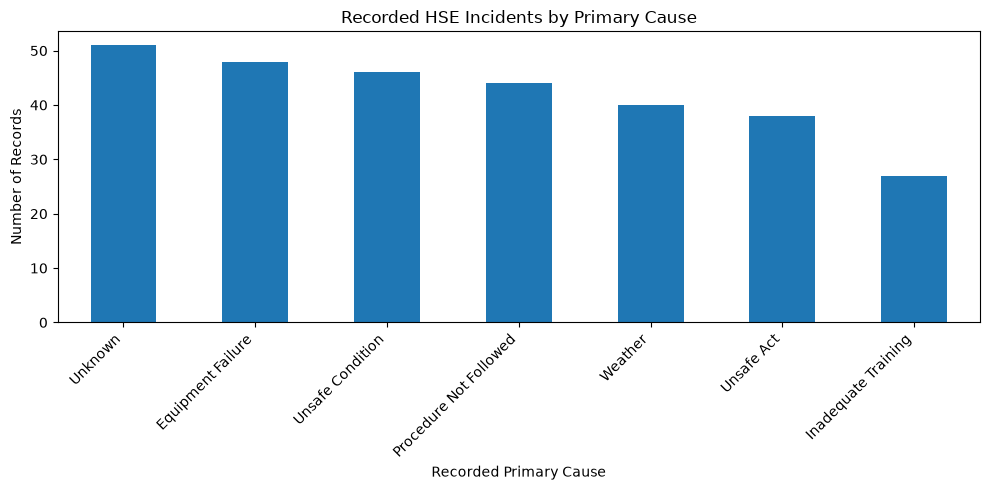

In [25]:
# Count recorded primary causes and calculate their percentage distribution.
primary_cause_counts = df_clean["Primary_Cause"].value_counts()
primary_cause_percentage = (df_clean["Primary_Cause"].value_counts(normalize=True) * 100).round(2)
display(primary_cause_counts)
display(primary_cause_percentage)

# Compare the recorded primary-cause categories.
primary_cause_counts.plot(kind="bar", figsize=(10, 5))
plt.title("Recorded HSE Incidents by Primary Cause")
plt.xlabel("Recorded Primary Cause")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 6.4 Incident Analysis by Site

This comparison shows how recorded incidents are distributed across sites. Counts are not incident rates; fairer comparisons require exposure information such as workforce hours.

Site
Gas Processing Plant    67
Pipeline Operations     66
Offshore Platform B     62
Onshore Base            53
Offshore Platform A     52
Name: count, dtype: int64

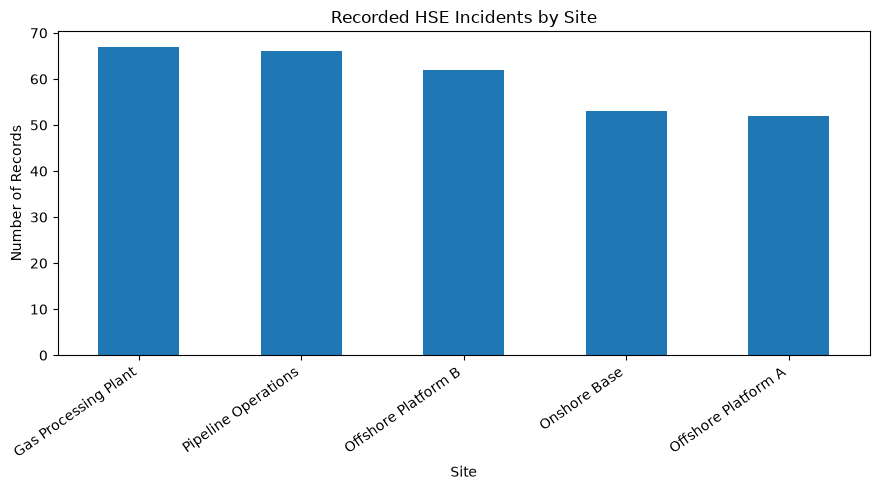

In [26]:
# Count recorded incidents by site.
site_incident_counts = df_clean["Site"].value_counts()
display(site_incident_counts)

# Compare incident counts across sites.
site_incident_counts.plot(kind="bar", figsize=(9, 5))
plt.title("Recorded HSE Incidents by Site")
plt.xlabel("Site")
plt.ylabel("Number of Records")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### 6.5 Near-Miss Analysis by Site

Near-miss records can reveal potential hazards. Differences in counts may also reflect reporting practices and levels of operational exposure.

Site
Offshore Platform B     26
Gas Processing Plant    23
Pipeline Operations     21
Onshore Base            18
Offshore Platform A     17
Name: count, dtype: int64

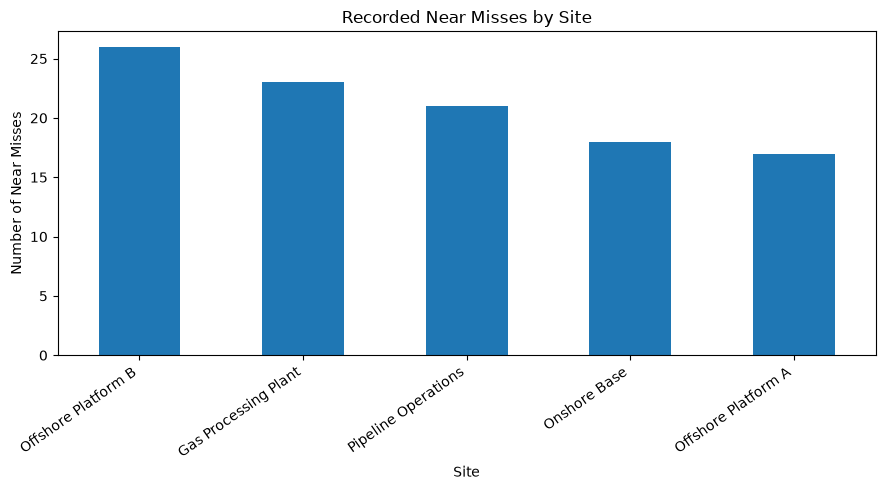

In [27]:
# Filter near-miss records using the standardised category label.
near_miss_data = df_clean[df_clean["Incident_Type"] == "Near Miss"].copy()

# Count near misses by site.
near_miss_by_site = near_miss_data["Site"].value_counts()
display(near_miss_by_site)

# Compare near-miss counts by site.
near_miss_by_site.plot(kind="bar", figsize=(9, 5))
plt.title("Recorded Near Misses by Site")
plt.xlabel("Site")
plt.ylabel("Number of Near Misses")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### 6.6 Near-Miss Analysis by Primary Cause

This analysis compares the recorded causes associated with near misses. Missing and unknown cause values limit conclusions.

Primary_Cause
Procedure Not Followed    20
Unknown                   18
Weather                   15
Unsafe Act                15
Equipment Failure         14
Unsafe Condition          11
Inadequate Training       11
Name: count, dtype: int64

Primary_Cause
Procedure Not Followed    19.23
Unknown                   17.31
Weather                   14.42
Unsafe Act                14.42
Equipment Failure         13.46
Unsafe Condition          10.58
Inadequate Training       10.58
Name: proportion, dtype: float64

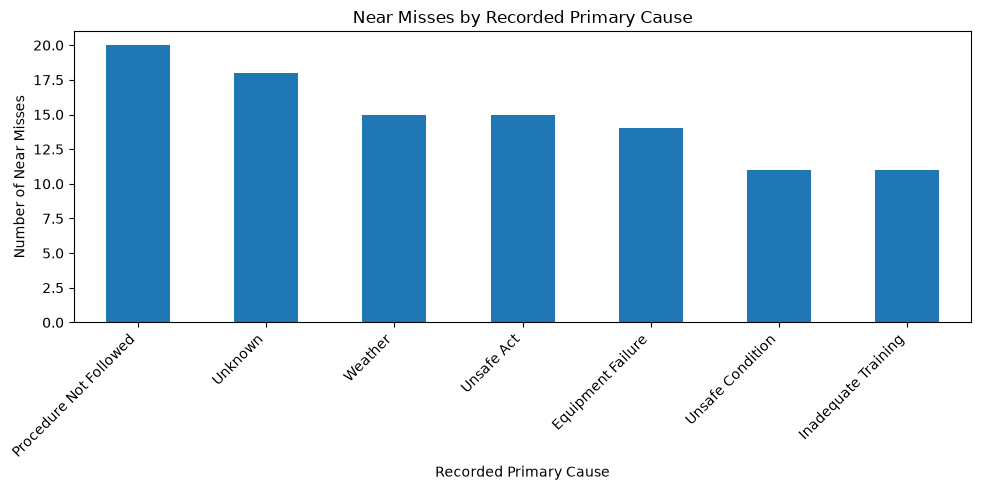

In [28]:
# Count recorded primary causes among near-miss records.
near_miss_by_cause = near_miss_data["Primary_Cause"].value_counts()
near_miss_cause_percentage = (near_miss_data["Primary_Cause"].value_counts(normalize=True) * 100).round(2)
display(near_miss_by_cause)
display(near_miss_cause_percentage)

# Compare recorded near-miss cause categories.
near_miss_by_cause.plot(kind="bar", figsize=(10, 5))
plt.title("Near Misses by Recorded Primary Cause")
plt.xlabel("Recorded Primary Cause")
plt.ylabel("Number of Near Misses")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 6.7 Near-Miss Analysis by Work Activity

This analysis compares near-miss counts across work activities. Counts alone do not establish which activity is riskiest because activity frequency and duration are not included.

Activity
Hot Work                 16
Lifting Operation        14
Equipment Maintenance    14
Driving                  14
Working At Height        12
Confined Space Entry      9
Material Handling         9
Routine Inspection        9
Housekeeping              8
Name: count, dtype: int64

Activity
Hot Work                 15.24
Lifting Operation        13.33
Equipment Maintenance    13.33
Driving                  13.33
Working At Height        11.43
Confined Space Entry      8.57
Material Handling         8.57
Routine Inspection        8.57
Housekeeping              7.62
Name: proportion, dtype: float64

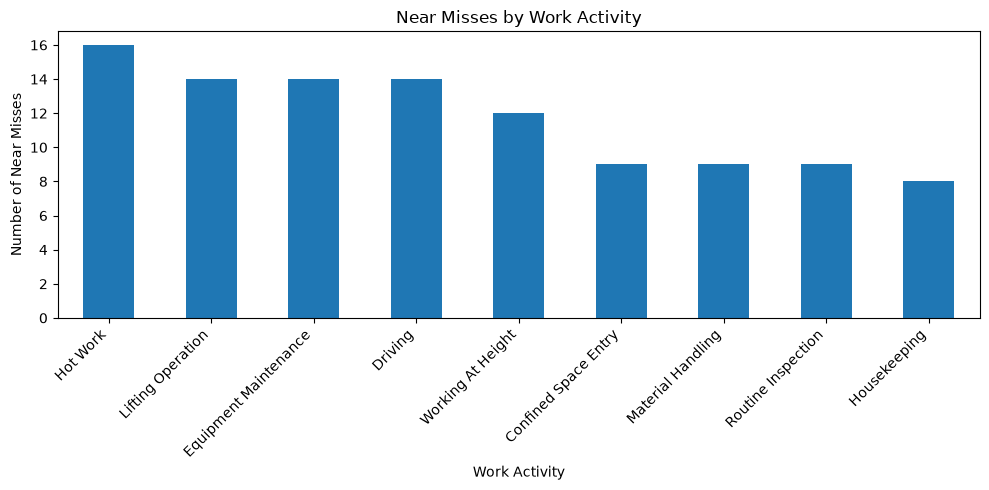

In [29]:
# Count near misses by recorded work activity.
near_miss_by_activity = near_miss_data["Activity"].value_counts()
near_miss_activity_percentage = (near_miss_data["Activity"].value_counts(normalize=True) * 100).round(2)
display(near_miss_by_activity)
display(near_miss_activity_percentage)

# Compare near-miss counts by work activity.
near_miss_by_activity.plot(kind="bar", figsize=(10, 5))
plt.title("Near Misses by Work Activity")
plt.xlabel("Work Activity")
plt.ylabel("Number of Near Misses")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 6.8 Monthly Incident Trend Analysis

Monthly counts show fluctuations over time. Five records have missing dates in the known cleaned dataset; mixed date formats create ambiguity, and October 2026 has only one dated record and should be treated as provisional.

Incident_Date
2025-01-01    11
2025-02-01    11
2025-03-01    13
2025-04-01    14
2025-05-01    19
2025-06-01    16
2025-07-01    11
2025-08-01    11
2025-09-01    15
2025-10-01    13
2025-11-01    12
2025-12-01    15
2026-01-01    17
2026-02-01    17
2026-03-01    14
2026-04-01    23
2026-05-01    16
2026-06-01    12
2026-07-01    11
2026-08-01    13
2026-09-01    10
2026-10-01     1
Freq: MS, dtype: int64

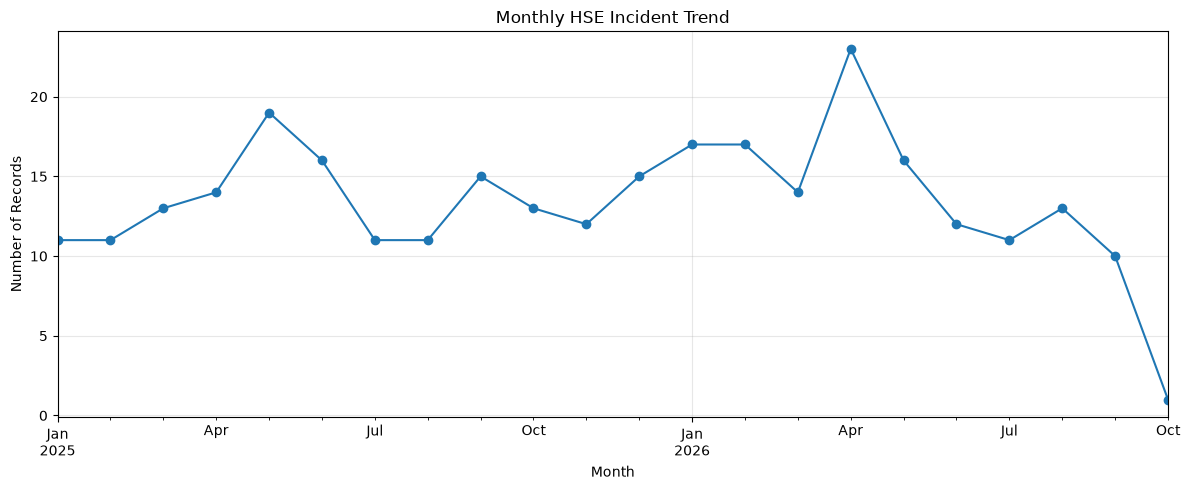

In [30]:
# Exclude records with missing dates from the monthly trend analysis.
dated_incidents = df_clean.dropna(subset=["Incident_Date"]).copy()

# Count records by calendar month.
monthly_incidents = dated_incidents.set_index("Incident_Date").resample("MS").size()
display(monthly_incidents)

# Visualise monthly incident counts.
monthly_incidents.plot(kind="line", figsize=(12, 5), marker="o")
plt.title("Monthly HSE Incident Trend")
plt.xlabel("Month")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 6.9 Severity by Incident Type

A cross-tabulation compares recorded severity categories within each incident type. This comparison depends on completeness and consistency of the classifications.

In [31]:
# Cross-tabulate incident type and severity.
severity_by_type = pd.crosstab(df_clean["Incident_Type"], df_clean["Severity"])
display(severity_by_type)

Severity,Critical,High,Low,Medium
Incident_Type,,,,
Environmental Release,0,11,0,14
First Aid,0,0,26,35
Lost Time Injury,0,23,0,0
Medical Treatment,0,22,0,16
Near Miss,1,0,103,0
Property Damage,0,17,13,15


### 6.10 High-Severity Incident Analysis by Site

This analysis counts High and Critical records by site. Counts can guide further review but cannot rank site safety without exposure information and operational context.

Site
Pipeline Operations     22
Gas Processing Plant    17
Onshore Base            13
Offshore Platform B     12
Offshore Platform A     10
Name: count, dtype: int64

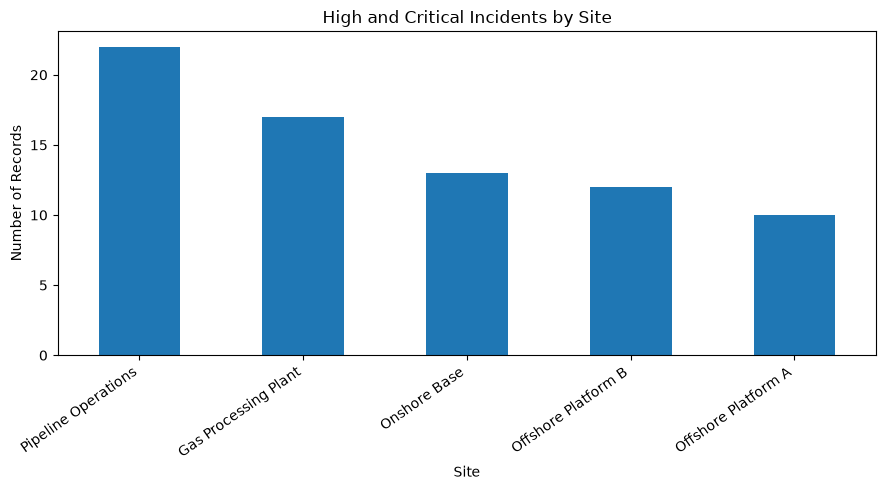

In [32]:
# Select records classified as High or Critical.
high_severity_data = df_clean[df_clean["Severity"].isin(["High", "Critical"])]

# Count High and Critical records by site.
high_severity_by_site = high_severity_data["Site"].value_counts()
display(high_severity_by_site)

# Compare high-severity incident counts by site.
high_severity_by_site.plot(kind="bar", figsize=(9, 5))
plt.title("High and Critical Incidents by Site")
plt.xlabel("Site")
plt.ylabel("Number of Records")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### 6.11 Summary of Key Findings

The exploratory analysis highlights patterns in incident types, severity classifications, recorded causes, work activities, site distributions, and monthly incident counts.

- Near misses were the most frequently recorded incident type in the cleaned dataset.
- Low severity was the most frequent recorded severity category; some records had missing severity values.
- Unknown causes and equipment failure were among the most frequently recorded primary-cause categories.
- Near-miss counts varied across sites and work activities.
- High-severity incident counts differed across sites, but counts alone do not establish relative risk.
- Monthly counts fluctuated over the study period; missing and ambiguous dates limit interpretation.

These findings describe simulated records and should not be presented as actual company safety performance.

## 7. Recommendations

Based on patterns in the simulated dataset, the following recommendations are proposed for consideration:

1. **Strengthen near-miss reporting and follow-up.** Encourage timely reporting and review so potential hazards can be investigated.
2. **Review recurring incident categories.** Examine frequently recorded incident types, causes, and activities to determine whether preventive controls need review.
3. **Investigate high-severity incidents.** Verify the circumstances and recorded causes of High and Critical incidents and assess existing controls.
4. **Improve data quality.** Use consistent date formats, complete required fields, standardise categories, and investigate unusual values.
5. **Monitor corrective-action timelines.** Review long durations to identify possible delays without assuming every unusual value is an error.
6. **Use exposure-based indicators.** Where available, use workforce hours and operational exposure to calculate more meaningful incident rates across sites.

These recommendations are illustrative and should be validated against actual operational records before being applied in a workplace.

## 8. Conclusion

This project demonstrated how Python can be used to clean, prepare, and analyse HSE incident records. Using Pandas, NumPy, and Matplotlib, the analysis explored incident types, severity classifications, recorded causes, work activities, site distributions, near misses, and monthly trends.

The project highlights the importance of data quality, cautious interpretation, and context when assessing safety performance. Because the dataset is simulated, the findings do not represent an actual oil and gas company's performance. The notebook provides a practical demonstration of Python-based analysis applied to an HSE scenario.

### Limitations

- The dataset is simulated and may not reflect the complexity of real operational records.
- Missing fields limit some analyses.
- Mixed date formats create ambiguity for some dates and affect time-based interpretation.
- Incident counts do not account for workforce size, hours worked, or operational exposure.
- Recorded causes are not necessarily confirmed root causes.

## Appendix: Reproducibility Notes

- Place `oil_gas_hse_raw_data.csv` in the same folder as this notebook before running it.
- Run the notebook from top to bottom so the cleaned dataset is created before analysis cells use it.
- The notebook preserves the raw dataset in `df` and performs transformations on `df_clean`.
- Review ambiguous source dates before making strong claims about monthly trends.